# 03 · Engine report card (Track B, SIMULATED)
Real covariates, simulated outcome with planted synergistic, antagonistic and non-linear interactions. Everything below is read from `artifacts/results/benchmark.json`, which `scripts/run_benchmark.py` writes from measurement. **Semi-synthetic data measures the engine, not nature.**

In [1]:
import json, warnings
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from pathlib import Path
from synera_core.config import find_repo_root, get_settings
warnings.filterwarnings("ignore")
ROOT = find_repo_root()
C = dict(bg="#061424", panel="#0b2037", cyan="#16B5FF", green="#6FD65B", amber="#FFB547", red="#FF4D5E", teal="#19E3B1", text="#EAF2FB", muted="#8FA6BF")
plt.rcParams.update({"figure.facecolor": C["bg"], "axes.facecolor": C["bg"], "axes.edgecolor": C["muted"], "axes.labelcolor": C["text"],
    "text.color": C["text"], "xtick.color": C["muted"], "ytick.color": C["muted"], "grid.color": "#1c3a5c", "axes.grid": True, "grid.linewidth": 0.5,
    "axes.prop_cycle": plt.cycler(color=[C["cyan"], C["green"], C["amber"], C["red"], C["teal"]]), "figure.dpi": 110, "font.size": 9})
SEED = get_settings().seeds.global_seed
RES = ROOT / "artifacts" / "results"

In [2]:
B = json.loads((RES / "benchmark.json").read_text())
print("limitations recorded with the results:"); [print(" -", x) for x in B["limitations"]]

limitations recorded with the results:
 - Semi-synthetic benchmark: real covariates, simulated outcome with planted interactions. It measures the engine, not nature.
 - Full-stack strict FDR exceeds the nominal 5% target: SNR 1.0: 6.2%, SNR 2.0: 0.7%, SNR 5.0: 0.0%, SNR 20.0: 0.0%. Correlated stressors that stand in for a planted partner count as false discoveries here.
 - The marginal pairwise screen alone is far from FDR control (SNR 1.0: 92.0%, SNR 2.0: 92.4%, SNR 5.0: 92.7%, SNR 20.0: 92.8%): omitted planted interactions leak into correlated pairs. Conditional selection is what removes them.
 - Null calibration over 100 simulations: median lambda naive 4.11, HAC 14.32, block bootstrap 1.38 (1.0 = calibrated).
 - 8 attack/contamination cells are caught by the cryptographic hash but by no statistical detector.
 - Space-biology Track A has n=6/6/3/6; the minimum detectable interaction is large and no gene-level interaction passes FDR.


[None, None, None, None, None, None]

In [3]:
rows = []
for snr, v in B["discovery"]["by_snr"].items():
    for st, s in v["stages"].items():
        rows.append({"SNR": float(snr), "stage": st, "discoveries": s["discoveries"], "true": s["true_positives"], "proxy": s["proxy"], "hard decoy": s["hard_decoy"], "easy decoy": s["easy_decoy"],
                     "recall": round(s["recall"], 2), "FDR strict": None if s["fdr_strict"] is None else round(s["fdr_strict"], 3), "FDR proxy-aware": None if s["fdr_proxy_aware"] is None else round(s["fdr_proxy_aware"], 3)})
T = pd.DataFrame(rows); display(T.pivot(index="stage", columns="SNR", values="FDR strict"))
display(T[T.stage.isin(["marginal_boot", "conditional", "full_stack"])].sort_values(["SNR", "stage"]))

SNR,1.0,2.0,5.0,20.0
stage,,,,
conditional,0.073,0.007,0.013,0.007
effect_gate,0.073,0.007,0.007,0.000
full_stack,0.062,0.007,0.000,0.000
marginal_boot,0.920,0.924,0.927,0.928
marginal_hac,0.929,0.932,0.933,0.933
marginal_naive,0.928,0.931,0.933,0.933


,SNR,stage,discoveries,true,proxy,hard decoy,easy decoy,recall,FDR strict,FDR proxy-aware
3,1.0,conditional,150,139,10,0,1,0.93,0.073,0.007
5,1.0,full_stack,144,135,9,0,0,0.90,0.062,0.000
2,1.0,marginal_boot,1870,150,350,956,414,1.00,0.920,0.901
9,2.0,conditional,150,149,1,0,0,0.99,0.007,0.000
11,2.0,full_stack,147,146,1,0,0,0.97,0.007,0.000
8,2.0,marginal_boot,1970,150,350,1023,447,1.00,0.924,0.907
15,5.0,conditional,152,150,0,0,2,1.00,0.013,0.013
17,5.0,full_stack,145,145,0,0,0,0.97,0.000,0.000
14,5.0,marginal_boot,2046,150,350,1072,474,1.00,0.927,0.912
21,20.0,conditional,151,150,0,0,1,1.00,0.007,0.007


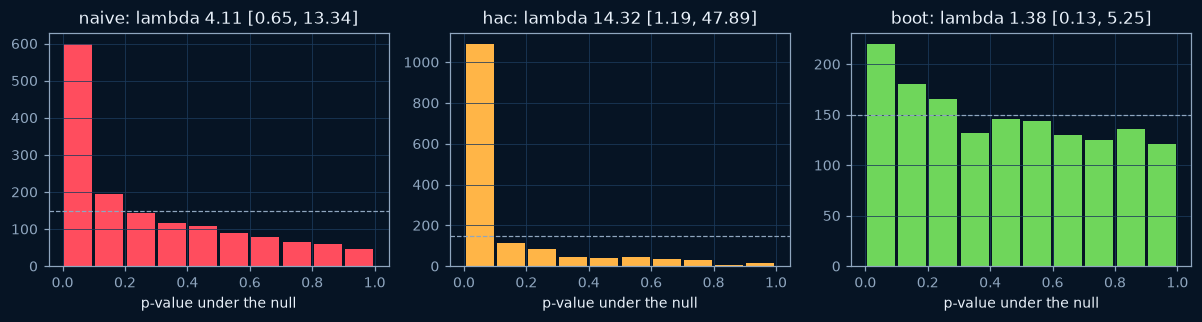

In [4]:
N = B["null_calibration"]
fig, axes = plt.subplots(1, 3, figsize=(11, 3))
for ax, m, col in zip(axes, ["naive", "hac", "boot"], [C["red"], C["amber"], C["green"]]):
    h = N[m]["p_histogram_10bins"]; ax.bar(np.arange(10) / 10 + 0.05, h, width=0.09, color=col); ax.axhline(sum(h) / 10, color=C["muted"], ls="--", lw=0.8)
    ax.set_title(f"{m}: lambda {N[m]['lambda_median']:.2f} [{N[m]['lambda_range'][0]:.2f}, {N[m]['lambda_range'][1]:.2f}]"); ax.set_xlabel("p-value under the null")
plt.tight_layout(); plt.show()

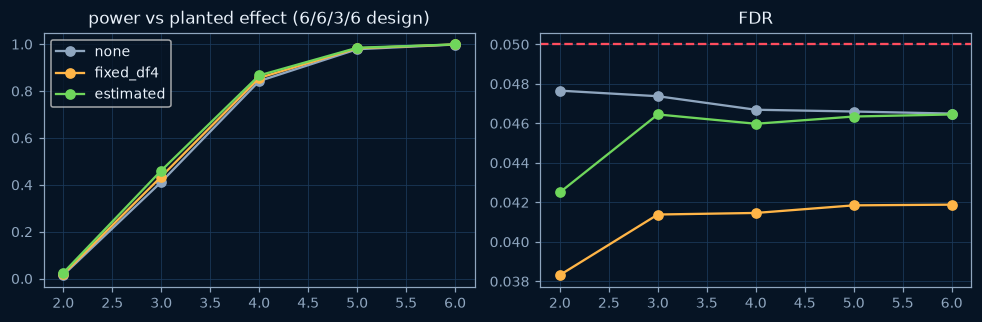

In [5]:
M = B["moderation"]["by_effect_sd"]; sizes = sorted(M, key=float)
fig, ax = plt.subplots(1, 2, figsize=(9, 3))
for meth, col in [("none", C["muted"]), ("fixed_df4", C["amber"]), ("estimated", C["green"])]:
    ax[0].plot([float(s) for s in sizes], [M[s][meth]["power_mean"] for s in sizes], "o-", color=col, label=meth)
    ax[1].plot([float(s) for s in sizes], [M[s][meth]["fdr_mean"] for s in sizes], "o-", color=col)
ax[0].set_title("power vs planted effect (6/6/3/6 design)"); ax[1].axhline(0.05, color=C["red"], ls="--"); ax[1].set_title("FDR"); ax[0].legend(); plt.tight_layout(); plt.show()